## Exercise 1

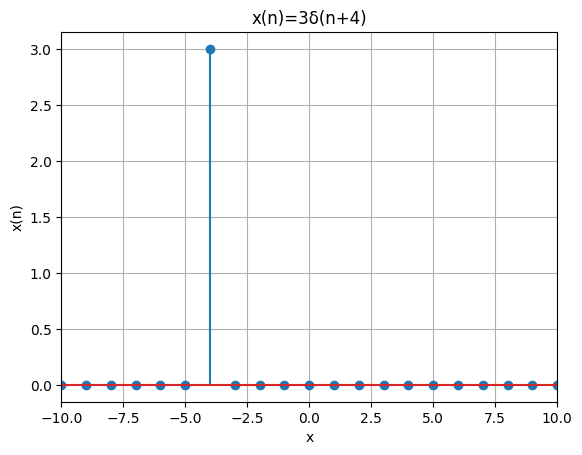

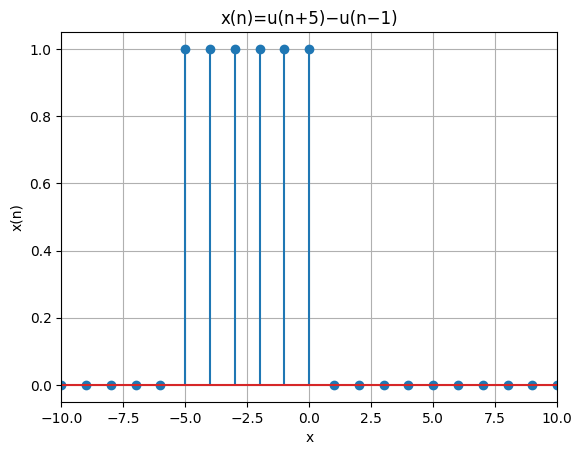

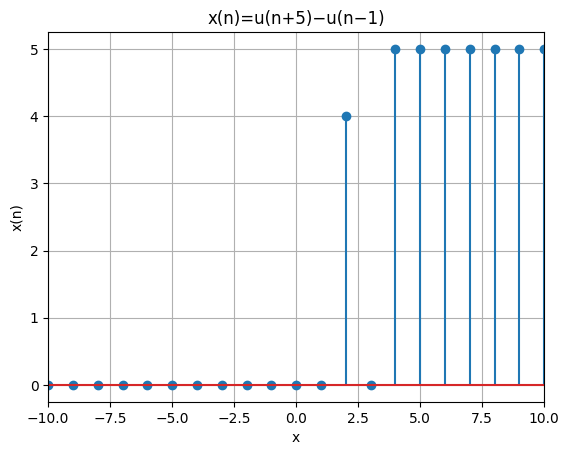

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt

# We define the delta and unit functions
delta = lambda n: n==0
unit = lambda n: n>=0

n = range(-10, 11)

y1 = []
for i in range(len(n)):
    temp = 3*delta(n[i] + 4)
    y1.append(temp)

plt.stem(n, y1)
plt.xlim([-10, 10])
plt.xlabel('x')
plt.ylabel('x(n)')
plt.title('x(n)=3δ(n+4)')
plt.grid()
plt.show()

y2 = []
for i in range(len(n)):
    temp = unit(n[i] + 5) - unit(n[i] - 1)
    y2.append(temp)

plt.stem(n, y2)
plt.xlim([-10, 10])
plt.xlabel('x')
plt.ylabel('x(n)')
plt.title('x(n)=u(n+5)−u(n−1)')
plt.grid()
plt.show()

y3 = []
for i in range(len(n)):
    temp = 4*delta(n[i]-2) + 5*unit(n[i]-4)
    y3.append(temp)

plt.stem(n, y3)
plt.xlim([-10, 10])
plt.xlabel('x')
plt.ylabel('x(n)')
plt.title(' x(n)=4δ(n−2)+5u(n−4)')
plt.grid()
plt.show()

# Exercise 2

In [14]:
import numpy as np

x = np.array([1, -1, 1, -1])
h = np.array([0.5, 1, -0.5, 0.5])

def circular_convolution(x, h):
    N = len(x)
    y = np.zeros(N)

    for n in range(N):
        for k in range(N):
            y[n] += x[k] * h[(n - k) % N]

    return y

y2 = circular_convolution(x, h)
print("Circular Convolution):", y2)

Circular Convolution): [-1.5  1.5 -1.5  1.5]


## Exercise 3

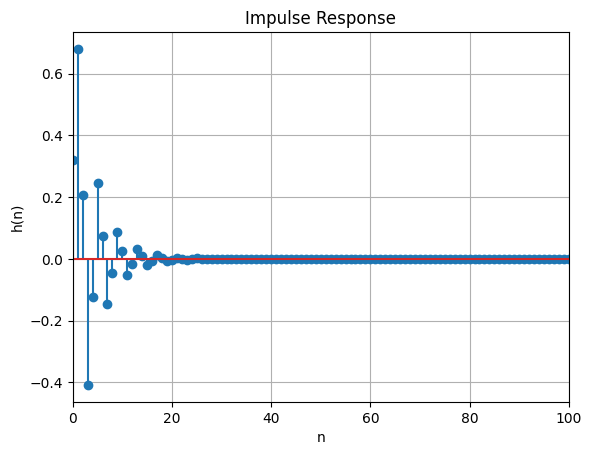

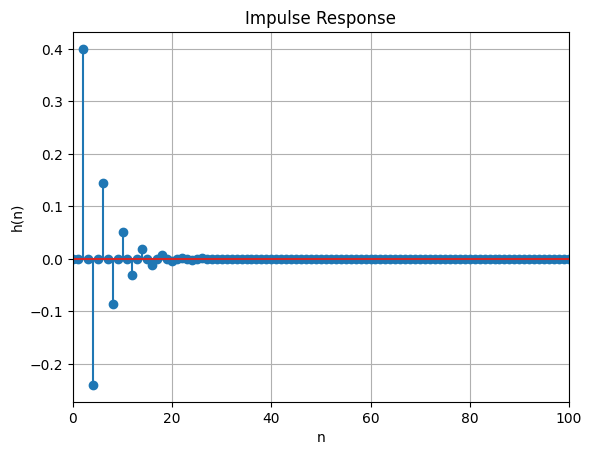

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import signal

# We define the delta and unit functions
delta = lambda n: n==0
unit = lambda n: n>=0


# first way
x=np.zeros(101)

a = [0.32,0.68,0.4]
b = [1,0,0.6]

for i in range(0,101,1):
    temp=int(delta(i))
    x[i]=temp
    
h = signal.lfilter(a,b,x)
plt.stem(h)
plt.xlabel('n')
plt.ylabel('h(n)')
plt.title('Impulse Response')
plt.xlim(0, 100)
plt.grid()
plt.show()

# second way

n = range(0, 101, 1)

x = np.zeros(101)
h = np.zeros(101)
for i in range(2, len(n), 1):
    h[i] = 0.32*int(delta(n[i])) + 0.68*int(delta(n[i]-1)) + 0.4*int(delta(n[i]-2)) - 0.6*h[i-2]

plt.stem(n, h)
plt.xlabel('n')
plt.ylabel('h(n)')
plt.title('Impulse Response')
plt.xlim(0, 100)
plt.grid()
plt.show()


## Exercise 4

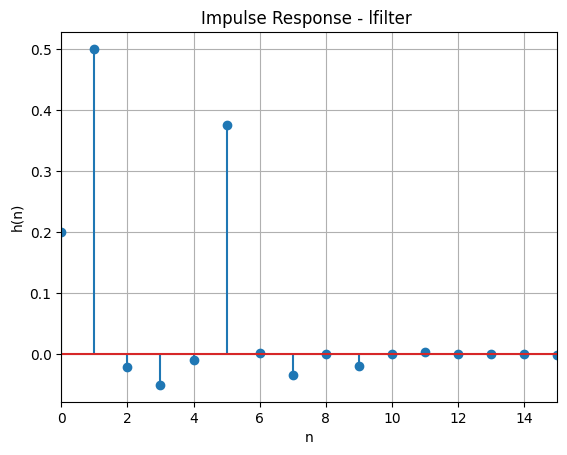

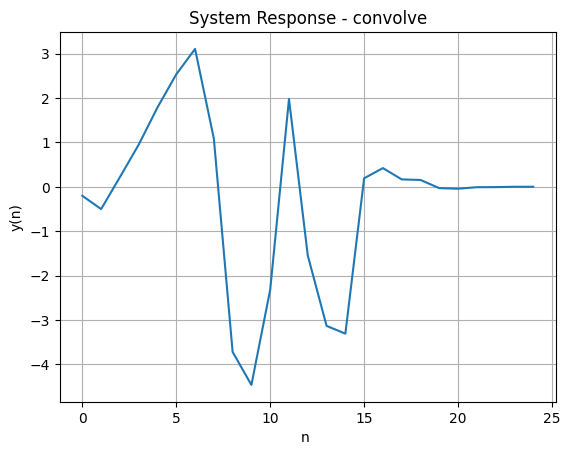

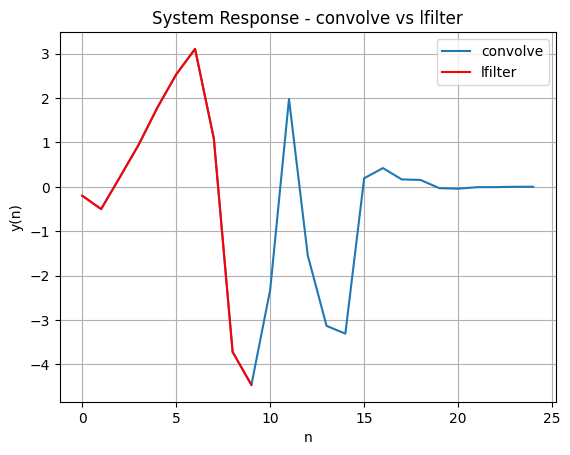

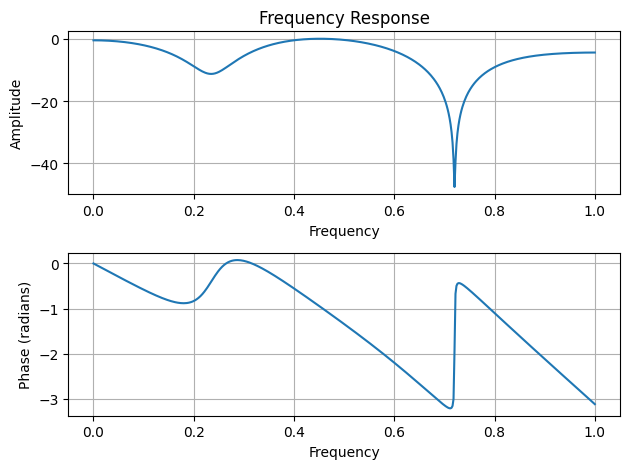

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import signal

delta = lambda n: n==0

# y(n) = 0.2x(n) + 0.5x(n-1) + 0.4x(n-5) - 0.1y(n-2) - 0.06y(n-4)
b = [0.2,0.5,0,0,0,0.4]
a = [1,0,0.1,0,0.06]

# a)
n = range(0,16,1)
x = np.zeros(16)
for i in range(0,16,1):
    x[i] = int(delta(i))

h = scipy.signal.lfilter(b, a, x)

plt.stem(n, h)
plt.xlabel('n')
plt.ylabel('h(n)')
plt.title('Impulse Response - lfilter ')
plt.xlim(0,15)
plt.grid()
plt.show()

# b)
x=np.array([-1,0,1,2,4,5,4,-5,-8,-9])

y=np.convolve(x,h)

plt.plot(y)
plt.xlabel('n ')
plt.ylabel('y(n)')
plt.title('System Response - convolve')
plt.grid()
plt.show()

# c)
y2 = scipy.signal.lfilter(b, a, x)

plt.plot(y,label='convolve')
plt.plot(y2,'r',label='lfilter')
plt.xlabel('n')
plt.ylabel('y(n)')
plt.title('System Response - convolve vs lfilter')
plt.legend()
plt.grid()
plt.show()

# d)
w, h = scipy.signal.freqz(b, a)
angles = np.unwrap(np.angle(h))

plt.subplot(2, 1, 1)
plt.plot(w/max(w), 20 * np.log10(abs(h)))
plt.xlabel('Frequency')
plt.ylabel('Amplitude')
plt.title('Frequency Response')
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(w/max(w), angles)
plt.xlabel('Frequency')
plt.ylabel('Phase (radians)')
plt.grid()

plt.tight_layout()
plt.show()

# Exercise 5

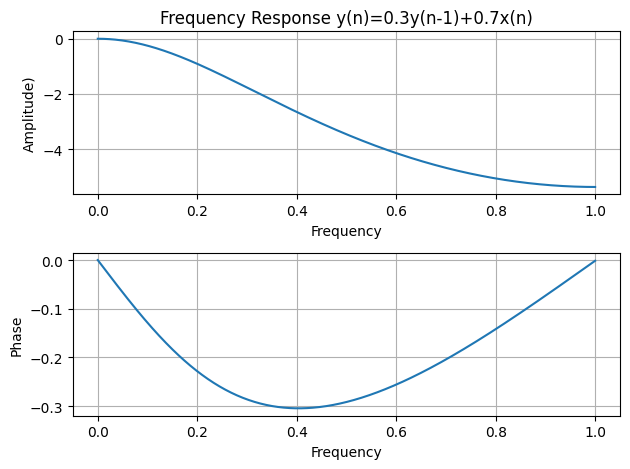

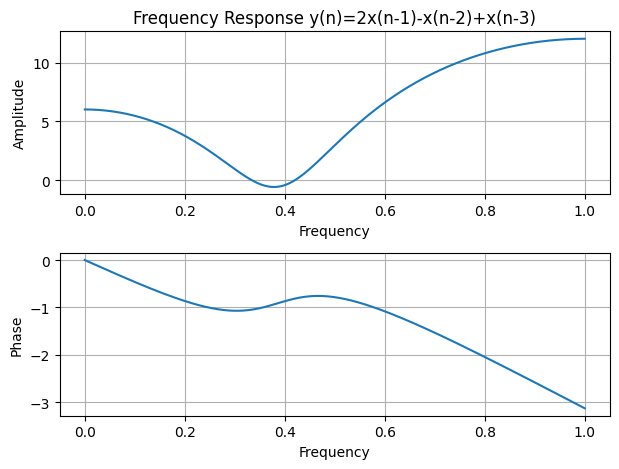

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import signal

#a) y(n) = 0.3y(n-1) + 0.7x(n) 
b = [0.7]
a = [1, -0.3]

w, h = scipy.signal.freqz(b, a)
angles = np.unwrap(np.angle(h))

plt.subplot(2, 1, 1)
plt.plot(w/max(w), 20 * np.log10(abs(h)))
plt.title('Frequency Response y(n)=0.3y(n-1)+0.7x(n)')
plt.xlabel('Frequency')
plt.ylabel('Amplitude)')
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(w/max(w), angles)
plt.xlabel('Frequency')
plt.ylabel('Phase')
plt.grid()

plt.tight_layout()
plt.show()

#b) y(n) = 2x(n-1) - x(n-2) + x(n-3) 
b = [0, 2, -1, 1]
a = [1]

w, h = scipy.signal.freqz(b, a)
angles = np.unwrap(np.angle(h))

plt.subplot(2, 1, 1)
plt.plot(w/max(w), 20 * np.log10(abs(h)))
plt.title('Frequency Response y(n)=2x(n-1)-x(n-2)+x(n-3)')
plt.xlabel('Frequency')
plt.ylabel('Amplitude')
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(w/max(w), angles)
plt.xlabel('Frequency')
plt.ylabel('Phase')
plt.grid()

plt.tight_layout()
plt.show()